# 04b — RDKit-Based QSAR Modeling of EGFR Inhibitory Activity

## Project Overview

This notebook extends the existing machine learning framework for predicting epidermal growth factor receptor (EGFR) inhibitory activity using quantitative structure–activity relationship (QSAR) modeling.

Molecular descriptors will be calculated from canonical SMILES using RDKit to characterize the physicochemical, constitutional, and topological properties of EGFR-associated compounds. These descriptors will be used as input features for additional supervised regression models predicting continuous pIC50 values.

The objective is to evaluate whether expanded molecular descriptors and alternative machine learning algorithms improve the prediction of EGFR inhibitory potency compared with previously developed models.

## Objectives

1. Load the previously curated EGFR activity dataset.
2. Calculate an expanded set of RDKit molecular descriptors.
3. Perform descriptor quality control and preprocessing.
4. Train three additional QSAR regression models:
   - Partial Least Squares (PLS) Regression
   - Support Vector Regression (SVR)
   - Random Forest Regression
5. Evaluate model performance using scaffold-based data splitting.
6. Compare results with previously developed EGFR prediction models.
7. Investigate important molecular descriptors associated with predicted inhibitory activity.

## Dataset

- **Target:** Epidermal Growth Factor Receptor (EGFR)
- **Training dataset:** 10,381 compounds
- **Molecular representation:** Canonical SMILES
- **Prediction target:** Continuous pIC50
- **Descriptor generation:** RDKit
- **Evaluation metrics:** R², RMSE, MAE

## Expected Outputs

- Curated RDKit molecular descriptor matrix
- Trained QSAR regression models
- Model performance comparison table
- Experimental versus predicted pIC50 plots
- Molecular descriptor importance analysis

## 1. Environment Setup and Library Imports

Required Python libraries are imported for molecular descriptor calculation, dataset processing, machine learning, and visualization. RDKit will be used to generate molecular representations, while scikit-learn will be used for QSAR model development and evaluation.

In [4]:
# Data handling
import pandas as pd
import numpy as np
from pathlib import Path

# Molecular descriptors
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

# Machine learning
from sklearn.cross_decomposition import PLSRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Model evaluation
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Model saving
import joblib

# Project directory
PROJECT_ROOT = Path("..").resolve()

print("Project directory:", PROJECT_ROOT)
print("RDKit QSAR environment ready.")

Project directory: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery
RDKit QSAR environment ready.


## 2. EGFR Dataset Loading

The previously curated EGFR activity dataset is loaded from the project's processed data directory. This dataset contains molecular structures represented as SMILES strings and experimentally derived pIC50 values.

Using the existing dataset ensures consistency with the previously developed machine learning models and allows direct comparison of predictive performance.

In [5]:
data_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "egfr_molecule_activity_with_smiles.csv"
)

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

Dataset shape: (10381, 8)

Columns:
['molecule_chembl_id', 'median_ic50_nM', 'n_measurements', 'min_ic50_nM', 'max_ic50_nM', 'pIC50', 'canonical_smiles', 'valid_smiles']


,molecule_chembl_id,median_ic50_nM,n_measurements,min_ic50_nM,max_ic50_nM,pIC50,canonical_smiles,valid_smiles
0,CHEMBL10,53000.0,2,10000.0,96000.0,4.275724,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,True
1,CHEMBL1009,2880.0,1,2880.0,2880.0,5.540608,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,True
2,CHEMBL101253,457.7,1,457.7,457.7,6.339419,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,True
3,CHEMBL1016,3276.9,1,3276.9,3276.9,5.484537,CCOc1nc2cccc(C(=O)O)c2n1Cc1ccc(-c2ccccc2-c2nnn...,True
4,CHEMBL101683,7300.0,1,7300.0,7300.0,5.136677,O=C(Nc1ccc(Cl)cc1)c1ccccc1NCc1ccncc1,True



Missing values:


molecule_chembl_id    0
median_ic50_nM        0
n_measurements        0
min_ic50_nM           0
max_ic50_nM           0
pIC50                 0
canonical_smiles      0
valid_smiles          0
dtype: int64

## 3. RDKit Molecular Descriptor Generation

Molecular structures were converted from canonical SMILES into
RDKit molecule objects. A comprehensive set of two-dimensional
molecular descriptors was calculated to characterize the
physicochemical and structural properties of each compound.

These descriptors will serve as input features for additional
QSAR regression models predicting continuous pIC50 values.

In [6]:
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd
import numpy as np

# Convert SMILES into RDKit molecule objects
molecules = [
    Chem.MolFromSmiles(smiles)
    for smiles in df["canonical_smiles"]
]

print("Total molecules:", len(molecules))
print("Valid molecules:", sum(mol is not None for mol in molecules))

# Initialize RDKit descriptor calculator
descriptor_names = [name for name, _ in Descriptors._descList]
calculator = Descriptors.CalcMolDescriptors

# Calculate descriptors for each molecule
descriptor_data = [
    calculator(mol) if mol is not None else {}
    for mol in molecules
]

# Create descriptor matrix
X_descriptors = pd.DataFrame(
    descriptor_data,
    index=df.index
)

print("Descriptor matrix shape:", X_descriptors.shape)

display(X_descriptors.head())

Total molecules: 10381
Valid molecules: 10381
Descriptor matrix shape: (10381, 217)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,13.337707,13.337707,0.288773,-1.027544,0.525196,12.111111,377.444,361.316,377.099811,134,...,0,0,0,0,0,0,0,0,0,0
1,10.418624,10.418624,0.114259,-1.099477,0.512507,12.357143,197.190,186.102,197.068808,76,...,0,0,0,0,0,0,0,0,0,0
2,5.947311,5.947311,0.702955,0.702955,0.563825,10.760000,346.821,331.701,346.098524,122,...,0,0,0,0,0,0,0,0,0,0
3,11.819107,11.819107,0.191822,-1.001242,0.392116,11.060606,440.463,420.303,440.159689,164,...,0,0,0,0,1,0,0,0,0,0
4,12.537070,12.537070,0.171157,-0.171157,0.715056,10.208333,337.810,321.682,337.098190,120,...,0,0,0,0,0,0,0,0,0,0


## 4. Descriptor Matrix Export and Quality Control

The calculated RDKit molecular descriptors were exported to preserve
the feature matrix and avoid repeating computationally expensive
descriptor calculations.

Descriptor quality control was subsequently performed to identify
missing values, infinite values, and non-informative features before
training QSAR regression models.

In [7]:
# Save the complete descriptor matrix
descriptor_path = PROJECT_ROOT / "data" / "processed" / "egfr_rdkit_descriptors.csv"

descriptor_path.parent.mkdir(parents=True, exist_ok=True)

X_descriptors.to_csv(descriptor_path, index=False)

print("Descriptors saved to:", descriptor_path)
print("Matrix shape:", X_descriptors.shape)

Descriptors saved to: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/data/processed/egfr_rdkit_descriptors.csv
Matrix shape: (10381, 217)


In [8]:
# Ensure all descriptor values are numeric
X_numeric = X_descriptors.apply(pd.to_numeric, errors="coerce")

# Count missing and infinite values
missing_values = X_numeric.isna().sum().sum()

infinite_values = np.isinf(
    X_numeric.to_numpy(dtype=float)
).sum()

# Identify constant descriptors
constant_features = X_numeric.columns[
    X_numeric.nunique(dropna=True) <= 1
]

print("Total descriptors:", X_numeric.shape[1])
print("Missing values:", missing_values)
print("Infinite values:", infinite_values)
print("Constant descriptors:", len(constant_features))

print("\nConstant descriptor names:")
print(constant_features.tolist())

Total descriptors: 217
Missing values: 152
Infinite values: 0
Constant descriptors: 10

Constant descriptor names:
['SMR_VSA8', 'SlogP_VSA9', 'fr_barbitur', 'fr_benzodiazepine', 'fr_diazo', 'fr_isocyan', 'fr_lactam', 'fr_phos_acid', 'fr_phos_ester', 'fr_thiocyan']


## 5. Descriptor-Based QSAR Feature Preparation

The RDKit descriptor matrix was examined for missing, infinite,
and constant values. To prevent data leakage, missing-value
imputation and removal of non-informative features will be
performed within the model-training pipeline using only
the training data.

Continuous pIC50 values were retained as the regression target
to enable comparison with the previously developed
Morgan fingerprint-based models.

In [9]:
from sklearn.model_selection import train_test_split

# Predictor matrix
X = X_numeric.replace([np.inf, -np.inf], np.nan).copy()

# Continuous regression target
y = df["pIC50"].astype(float).copy()

# Confirm alignment
assert X.index.equals(y.index)

# Create an 80/20 random split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training compounds:", len(X_train))
print("Testing compounds:", len(X_test))
print("Descriptor features:", X.shape[1])
print("Target:", y.name)

Training compounds: 8304
Testing compounds: 2077
Descriptor features: 217
Target: pIC50


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler

descriptor_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("scaler", StandardScaler())
])

X_train_processed = descriptor_preprocessor.fit_transform(X_train)
X_test_processed = descriptor_preprocessor.transform(X_test)

print("Original descriptors:", X_train.shape[1])
print("Descriptors after preprocessing:", X_train_processed.shape[1])
print("Training matrix:", X_train_processed.shape)
print("Testing matrix:", X_test_processed.shape)

Original descriptors: 217
Descriptors after preprocessing: 207
Training matrix: (8304, 207)
Testing matrix: (2077, 207)


## 6. Descriptor-Based QSAR Model Training

Three supervised regression algorithms were evaluated using
RDKit-generated molecular descriptors: Ridge Regression,
Random Forest, and Gradient Boosting.

All models were trained to predict continuous pIC50 values.
Missing-value imputation, removal of constant descriptors,
and feature standardization were incorporated into each
model pipeline to prevent data leakage.

Model performance was evaluated using the held-out test set
with R², root mean squared error (RMSE), and mean absolute
error (MAE).

In [11]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.base import clone
import time

# Define regression models
models = {
    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")
    start = time.time()

    # Include preprocessing inside the model pipeline
    pipeline = Pipeline([
        ("preprocessing", clone(descriptor_preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "R2": r2_score(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "Training Time (s)": round(time.time() - start, 2)
    })

    trained_models[name] = pipeline

# Compare model performance
qsar_results = pd.DataFrame(results).sort_values(
    "R2", ascending=False
)

display(qsar_results)


Training Ridge Regression...

Training Random Forest...

Training Gradient Boosting...


,Model,R2,RMSE,MAE,Training Time (s)
1,Random Forest,0.637861,0.780975,0.596252,1.62
2,Gradient Boosting,0.628529,0.790973,0.610581,3.05
0,Ridge Regression,0.364657,1.034436,0.811110,0.38


## 7. Comparison of Descriptor-Based QSAR Models

Predictive performance was compared across three regression
algorithms using RDKit molecular descriptors. Model performance
was assessed using R², RMSE, and MAE on the held-out test set.

A comparative visualization was generated to identify the
best-performing descriptor-based QSAR approach.

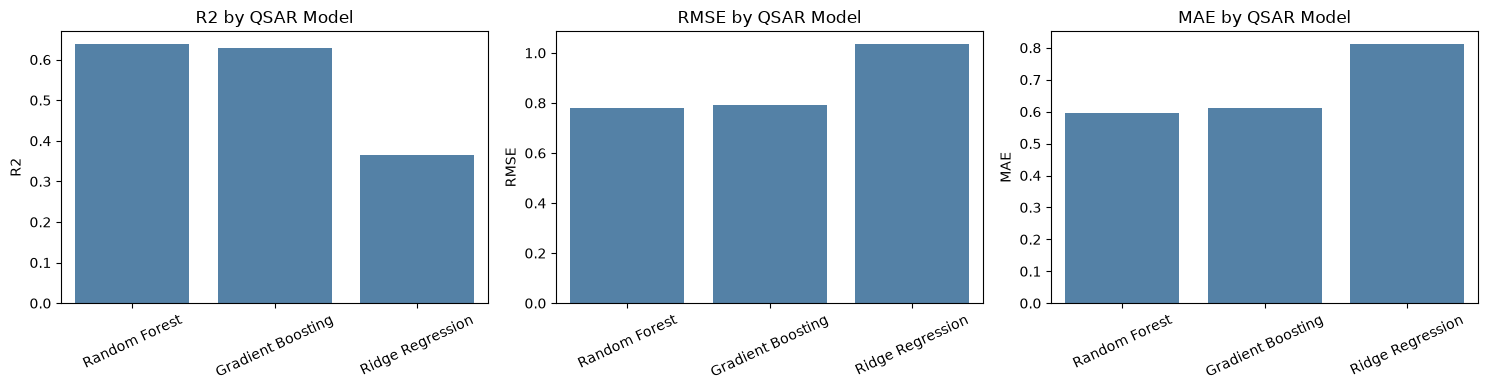

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/rdkit_qsar_model_comparison.png


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = ["R2", "RMSE", "MAE"]

for ax, metric in zip(axes, metrics):
    sns.barplot(
        data=qsar_results,
        x="Model",
        y=metric,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"{metric} by QSAR Model")
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()

figure_path = PROJECT_ROOT / "figures" / "rdkit_qsar_model_comparison.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

## 8. Scaffold-Based QSAR Model Evaluation

To assess the ability of descriptor-based QSAR models to
generalize to structurally distinct compounds, a scaffold-based
train/test split was performed using Bemis–Murcko scaffolds.

Molecules sharing the same scaffold were assigned exclusively
to either the training or testing set, preventing scaffold
overlap between the two partitions.

The Random Forest and Gradient Boosting models were
subsequently evaluated using R², RMSE, and MAE.

In [13]:
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupShuffleSplit

# Generate Bemis-Murcko scaffolds
def get_scaffold(mol):
    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

scaffolds = [
    get_scaffold(mol)
    for mol in molecules
]

# Scaffold-based 80/20 split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X_descriptors,
        df["pIC50"],
        groups=scaffolds
    )
)

X_train_scaffold = X_descriptors.iloc[train_idx]
X_test_scaffold = X_descriptors.iloc[test_idx]

y_train_scaffold = df["pIC50"].iloc[train_idx]
y_test_scaffold = df["pIC50"].iloc[test_idx]

# Verify scaffold separation
train_scaffolds = set(scaffolds[i] for i in train_idx)
test_scaffolds = set(scaffolds[i] for i in test_idx)

print("Training compounds:", len(train_idx))
print("Testing compounds:", len(test_idx))
print("Training scaffolds:", len(train_scaffolds))
print("Testing scaffolds:", len(test_scaffolds))
print("Shared scaffolds:", len(train_scaffolds & test_scaffolds))

Training compounds: 8416
Testing compounds: 1965
Training scaffolds: 2958
Testing scaffolds: 740
Shared scaffolds: 0


## 9. Scaffold-Based QSAR Model Training

Random Forest and Gradient Boosting regression models were
trained using RDKit molecular descriptors and a scaffold-based
train/test partition.

Descriptor preprocessing included median imputation, removal
of constant features, and standardization. Preprocessing was
fitted exclusively on training data to prevent data leakage.

Model performance was evaluated on structurally distinct
testing compounds using R², RMSE, and MAE.

In [14]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import time

# Models for scaffold-based evaluation
scaffold_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        random_state=42
    )
}

scaffold_results = []
scaffold_trained_models = {}

for name, model in scaffold_models.items():

    print(f"Training {name}...")

    # Fit preprocessing on training data only
    pipeline = Pipeline([
        ("preprocessor", clone(descriptor_preprocessor)),
        ("model", model)
    ])

    start = time.time()

    pipeline.fit(X_train_scaffold, y_train_scaffold)

    predictions = pipeline.predict(X_test_scaffold)

    scaffold_results.append({
        "Model": name,
        "R2": r2_score(y_test_scaffold, predictions),
        "RMSE": np.sqrt(mean_squared_error(
            y_test_scaffold, predictions
        )),
        "MAE": mean_absolute_error(
            y_test_scaffold, predictions
        ),
        "Training Time (s)": round(time.time() - start, 2)
    })

    scaffold_trained_models[name] = pipeline

# Display results
scaffold_results_df = pd.DataFrame(
    scaffold_results
).sort_values("R2", ascending=False)

display(scaffold_results_df)

Training Random Forest...
Training Gradient Boosting...


,Model,R2,RMSE,MAE,Training Time (s)
0,Random Forest,0.577578,0.824977,0.628180,19.17
1,Gradient Boosting,0.486846,0.909269,0.702112,37.38


## 10. Random-Split and Scaffold-Split Performance Comparison

Predictive performance was compared between random and
scaffold-based data partitions to evaluate the influence
of molecular structural similarity on model generalization.

Random Forest and Gradient Boosting models were evaluated
using RDKit-generated molecular descriptors.

Changes in R², RMSE, and MAE were examined to characterize
performance differences between the two evaluation strategies.

,Model,R2,RMSE,MAE,Training Time (s),Split
0,Random Forest,0.637861,0.780975,0.596252,1.62,Random
1,Gradient Boosting,0.628529,0.790973,0.610581,3.05,Random
2,Random Forest,0.577578,0.824977,0.628180,19.17,Scaffold
3,Gradient Boosting,0.486846,0.909269,0.702112,37.38,Scaffold


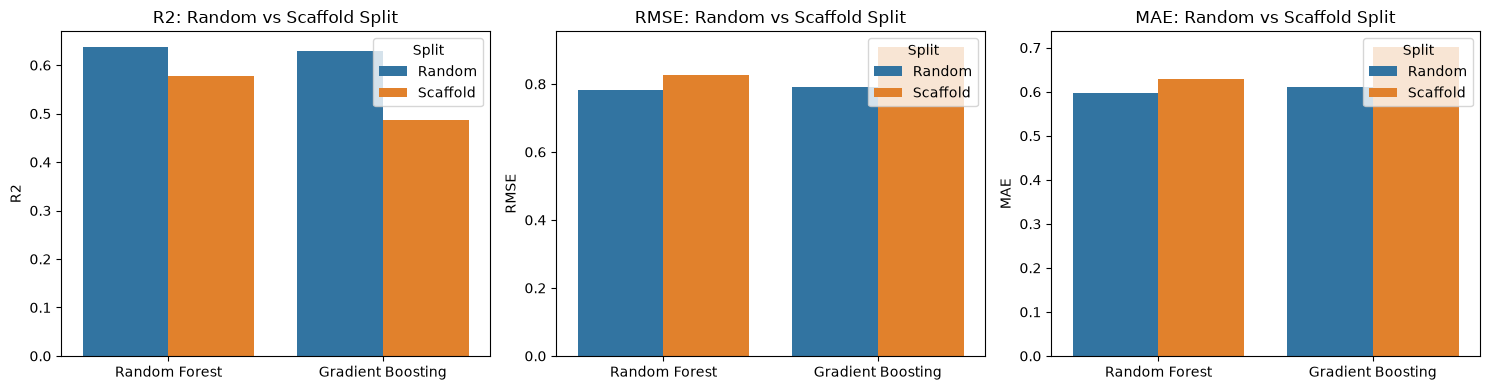

In [15]:
# Combine random-split and scaffold-split results

random_comparison = qsar_results[
    qsar_results["Model"].isin(
        ["Random Forest", "Gradient Boosting"]
    )
].copy()

random_comparison["Split"] = "Random"

scaffold_comparison = scaffold_results_df.copy()
scaffold_comparison["Split"] = "Scaffold"

comparison_df = pd.concat(
    [random_comparison, scaffold_comparison],
    ignore_index=True
)

display(comparison_df)

# Visualize performance
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric in zip(axes, ["R2", "RMSE", "MAE"]):

    sns.barplot(
        data=comparison_df,
        x="Model",
        y=metric,
        hue="Split",
        ax=ax
    )

    ax.set_title(f"{metric}: Random vs Scaffold Split")
    ax.set_xlabel("")
    ax.set_ylabel(metric)

plt.tight_layout()

figure_path = (
    PROJECT_ROOT / "figures" /
    "rdkit_qsar_random_vs_scaffold.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. RDKit Molecular Descriptor Feature Importance

Feature importance was evaluated for the Random Forest QSAR
model trained using RDKit-generated molecular descriptors.

The model's impurity-based feature importance scores were
extracted to identify the descriptors most frequently used
to reduce prediction error across the decision trees.

The 20 highest-ranking descriptors were visualized to
characterize the molecular properties contributing to
predicted EGFR inhibitory activity.

In [16]:
# Retrieve scaffold-trained Random Forest pipeline
rf_pipeline = scaffold_trained_models["Random Forest"]

# Extract fitted preprocessing and model
preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_model = rf_pipeline.named_steps["model"]

# Retrieve descriptor names after variance filtering
variance_filter = preprocessor.named_steps["variance"]

selected_features = X_descriptors.columns[
    variance_filter.get_support()
]

# Extract feature importance scores
importance_df = pd.DataFrame({
    "Descriptor": selected_features,
    "Importance": rf_model.feature_importances_
})

# Rank descriptors
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.head(20))

,Descriptor,Importance
0,SMR_VSA3,0.120082
1,fr_hdrzine,0.045609
2,SlogP_VSA10,0.041980
3,BCUT2D_CHGLO,0.027932
4,BCUT2D_LOGPHI,0.026371
5,BCUT2D_CHGHI,0.024718
6,BCUT2D_MRHI,0.022096
7,SMR_VSA7,0.020511
8,fr_aniline,0.017127
9,VSA_EState7,0.015600


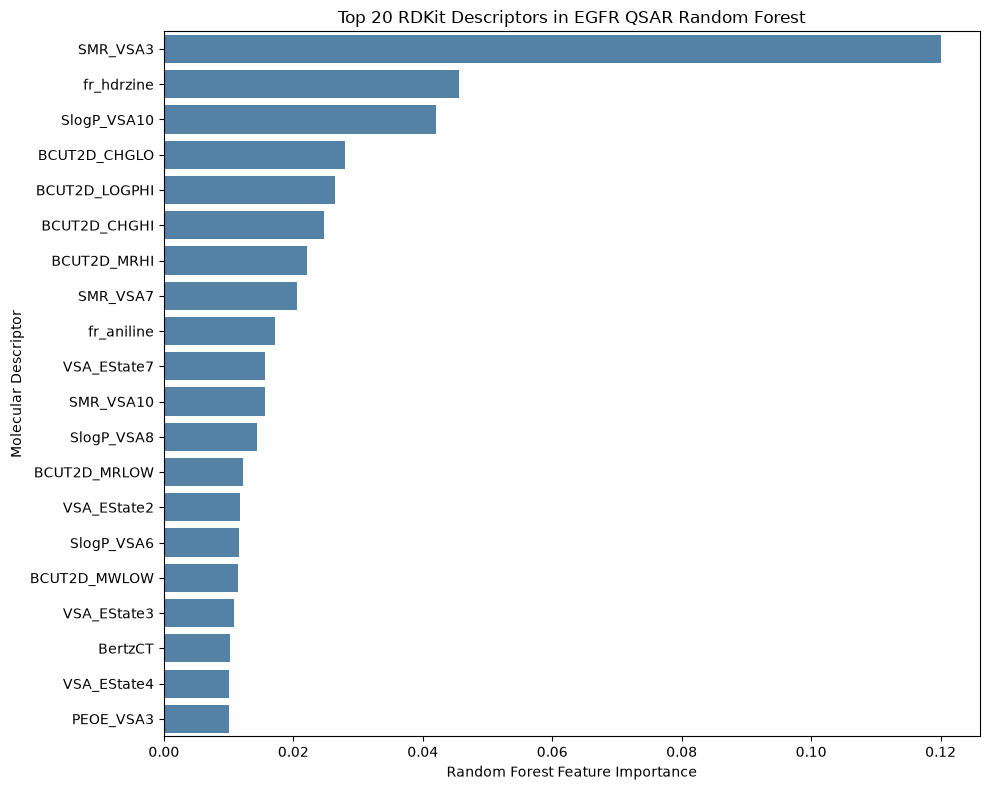

In [17]:
top_20 = importance_df.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_20,
    x="Importance",
    y="Descriptor",
    color="steelblue"
)

plt.title("Top 20 RDKit Descriptors in EGFR QSAR Random Forest")
plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Molecular Descriptor")

plt.tight_layout()

figure_path = (
    PROJECT_ROOT / "figures" /
    "rdkit_qsar_feature_importance.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

## 12. Model and Results Export

The trained RDKit descriptor-based QSAR models, model
performance metrics, and feature importance rankings
were exported for reproducibility and downstream analysis.

The scaffold-trained Random Forest model was retained
as the primary descriptor-based QSAR model because it
demonstrated the strongest predictive performance on
structurally distinct testing compounds.

In [18]:
# Create output directories
models_dir = PROJECT_ROOT / "results" / "models"
results_dir = PROJECT_ROOT / "results"

models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

# Save scaffold-trained Random Forest pipeline
joblib.dump(
    scaffold_trained_models["Random Forest"],
    models_dir / "egfr_rdkit_rf_scaffold.joblib"
)

# Save scaffold-trained Gradient Boosting pipeline
joblib.dump(
    scaffold_trained_models["Gradient Boosting"],
    models_dir / "egfr_rdkit_gb_scaffold.joblib"
)

# Save random-split model comparison
qsar_results.to_csv(
    results_dir / "rdkit_qsar_random_results.csv",
    index=False
)

# Save scaffold-split model comparison
scaffold_results_df.to_csv(
    results_dir / "rdkit_qsar_scaffold_results.csv",
    index=False
)

# Save descriptor feature importance
importance_df.to_csv(
    results_dir / "rdkit_descriptor_importance.csv",
    index=False
)

print("RDKit QSAR models and results saved successfully.")

RDKit QSAR models and results saved successfully.
